In [ ]:
from huggingface_hub import notebook_login
notebook_login()

In [ ]:
from dataclasses import dataclass

@dataclass
class Config:
    img_size = 128
    train_bs = 16
    eval_bs = 16
    epochs = 50
    grad_accum = 1
    lr = 1e-4
    warmup = 500
    save_img = 10
    save_model = 30
    precision = "fp16"
    out_dir = "ddpm-butterflies-128"
    seed = 0

config = Config()

In [ ]:
from datasets import load_dataset

config.dataset = "huggan/smithsonian_butterflies_subset"
dataset = load_dataset(config.dataset, split="train")

README.md:   0%|          | 0.00/609 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.65k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

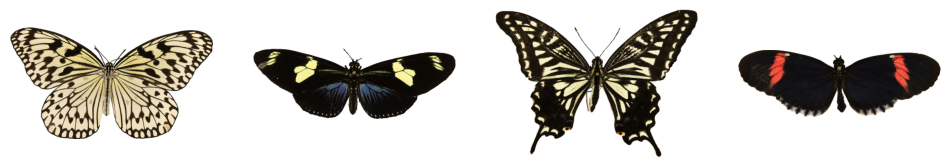

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, img in zip(ax, dataset[:4]["image"]):
    a.imshow(img)
    a.axis("off")
plt.show()

In [ ]:
from torchvision import transforms

preprocess = transforms.Compose(
    [
        transforms.Resize((config.img_size, config.img_size)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5]),
    ]
)

In [ ]:
def transform(ex):
    imgs = [preprocess(img.convert("RGB")) for img in ex["image"]]
    return {"images": imgs}

dataset.set_transform(transform)

In [ ]:
from torch.utils.data import DataLoader

train_dl = DataLoader(dataset,
    batch_size=config.train_bs,
    shuffle=True
)

In [ ]:
from diffusers import UNet2DModel

model = UNet2DModel(
    sample_size=config.img_size,
    in_channels=3,
    out_channels=3,
    layers_per_block=2,
    block_out_channels=(128, 128, 256, 256, 512, 512),
    down_block_types=(
        "DownBlock2D", "DownBlock2D", "DownBlock2D",
        "DownBlock2D", "AttnDownBlock2D", "DownBlock2D"
    ),
    up_block_types=(
        "UpBlock2D", "AttnUpBlock2D", "UpBlock2D",
        "UpBlock2D", "UpBlock2D", "UpBlock2D"
    ),
)

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [ ]:
img = dataset[0]["images"].unsqueeze(0)
print("Input:", img.shape)
print("Output:", model(img, timestep=0).sample.shape)

Input: torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 3, 128, 128])


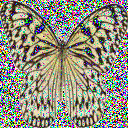

In [ ]:
import torch
from PIL import Image
from diffusers import DDPMScheduler

scheduler = DDPMScheduler(num_train_timesteps=1000)
noise = torch.randn(img.shape)
t = torch.LongTensor([50])
noisy = scheduler.add_noise(img, noise, t)

Image.fromarray(((noisy.permute(0, 2, 3, 1) + 1) * 127.5).byte().numpy()[0])

In [ ]:
import torch.nn.functional as F

noise_pred = model(noisy, t).sample
loss = F.mse_loss(noise_pred, noise)

In [ ]:
from diffusers.optimization import get_cosine_schedule_with_warmup as cos_sch
optimizer = torch.optim.AdamW(model.parameters(), lr=config.lr)
lr_scheduler = cos_sch(
    optimizer=optimizer,
    num_warmup_steps=config.warmup,
    num_training_steps=len(train_dl) * config.epochs,
)

In [ ]:
from diffusers import DDPMPipeline
from diffusers.utils import make_image_grid
import os

def evaluate(config, epoch, pipe):
    imgs = pipe(
        batch_size=config.eval_bs,
        generator=torch.Generator(device="cpu").manual_seed(config.seed),
    ).images

    grid = make_image_grid(imgs, rows=4, cols=4)
    path = os.path.join(config.out_dir, "samples")
    os.makedirs(path, exist_ok=True)
    grid.save(f"{path}/{epoch:04d}.png")

In [ ]:
from accelerate import Accelerator
from diffusers import DDPMPipeline
from tqdm.auto import tqdm
import os

def train_loop(c, model, sch, opt, dl, lr):
    acc = Accelerator(
        mixed_precision=c.precision,
        gradient_accumulation_steps=c.grad_accum,
        log_with="tensorboard",
        project_dir=os.path.join(c.out_dir, "logs")
    )

    if acc.is_main_process:
        os.makedirs(c.out_dir, exist_ok=True)
        acc.init_trackers("train")

    model, opt, dl, lr = acc.prepare(model, opt, dl, lr)
    step = 0

    for ep in range(c.epochs):
        bar = tqdm(dl, disable=not acc.is_local_main_process)
        bar.set_description(f"Epoch {ep}")

        for b in bar:
            x = b["images"]
            n = torch.randn_like(x)
            t = torch.randint(
                0, sch.config.num_train_timesteps,
                (x.shape[0],), device=x.device
            )
            noisy = sch.add_noise(x, n, t)

            with acc.accumulate(model):
                loss = F.mse_loss(model(noisy, t, return_dict=False)[0], n)
                acc.backward(loss)

                if acc.sync_gradients:
                    acc.clip_grad_norm_(model.parameters(), 1.0)

                opt.step()
                lr.step()
                opt.zero_grad()

            log = {"loss": loss.item(), "lr": lr.get_last_lr()[0]}
            bar.set_postfix(**log)
            acc.log(log, step=step)
            step += 1

        if acc.is_main_process:
            pipe = DDPMPipeline(
                unet=acc.unwrap_model(model),
                scheduler=sch
            )

            if (ep + 1) % c.save_img == 0 or ep == c.epochs - 1:
                evaluate(c, ep, pipe)

            if (ep + 1) % c.save_model == 0 or ep == c.epochs - 1:
                pipe.save_pretrained(c.out_dir)

In [ ]:
from accelerate import notebook_launcher

notebook_launcher(
    train_loop, (config, model, scheduler, optimizer, train_dl, lr_scheduler),
    num_processes=1
)

Launching training on one GPU.


  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

... (46 outputs left out)

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

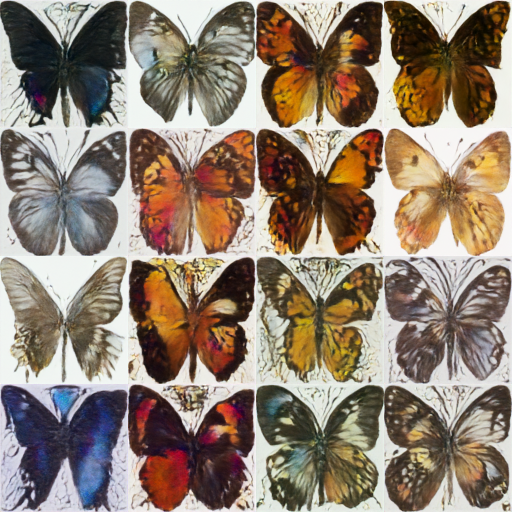

In [ ]:
import glob

imgs = sorted(glob.glob(f"{config.out_dir}/samples/*.png"))
Image.open(imgs[-1])